In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from itertools import combinations
import sys
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import os

## Prepare ENSEMBL+CHESS USE catalog

In [2]:
!mkdir "./gtfs"

In [3]:
%%time
#Rename chroms in ensembl
import pyranges as pr
df = pr.read_gtf('../../../arkuda_backup/gtfs/Homo_sapiens.GRCh38.108.chr.gtf.gz')

CPU times: total: 2min 20s
Wall time: 2min 25s


In [4]:
chroms = df.Chromosome.unique().tolist()

In [5]:
mapping = {i:'chrM' if i=='MT' else f'chr{i}' for i in chroms}
mapping

{'1': 'chr1',
 '2': 'chr2',
 '3': 'chr3',
 '4': 'chr4',
 '5': 'chr5',
 '6': 'chr6',
 '7': 'chr7',
 '8': 'chr8',
 '9': 'chr9',
 '10': 'chr10',
 '11': 'chr11',
 '12': 'chr12',
 '13': 'chr13',
 '14': 'chr14',
 '15': 'chr15',
 '16': 'chr16',
 '17': 'chr17',
 '18': 'chr18',
 '19': 'chr19',
 '20': 'chr20',
 '21': 'chr21',
 '22': 'chr22',
 'MT': 'chrM',
 'X': 'chrX',
 'Y': 'chrY'}

In [6]:
df.Chromosome = df.Chromosome.map(mapping)

In [7]:
df.to_gtf('./gtfs/Homo_sapiens.GRCh38.108.chr_chromnames.gtf')

In [8]:
cmd = 'wsl sh -c "gunzip -c ../../../arkuda_backup/gtfs/chess3.1.3.GRCh38.gtf.gz > ./gtfs/chess3.1.3.GRCh38.gtf"'
!{cmd}

In [11]:
!mkdir "./gtfs/merged"
exe = '/home/zavilev/soft/gffcompare/gffcompare'
ref = './gtfs/Homo_sapiens.GRCh38.108.chr_chromnames.gtf'
other = './gtfs/chess3.1.3.GRCh38.gtf'
prefix = './gtfs/merged/gffcompare'
command = f'{exe} -r {ref} -o {prefix} {other}'
cmd = f'wsl sh -c "{command}"'
print(cmd)

wsl sh -c "/home/zavilev/soft/gffcompare/gffcompare -r ./gtfs/Homo_sapiens.GRCh38.108.chr_chromnames.gtf -o ./gtfs/merged/gffcompare ./gtfs/chess3.1.3.GRCh38.gtf"


A subdirectory or file ./gtfs/merged already exists.


In [12]:
%%time
!{cmd}

CPU times: total: 1.25 s
Wall time: 6min 35s


### Filter and merge GTFs

In [13]:
merged = pr.read_gtf('./gtfs/merged/gffcompare.annotated.gtf').df

In [14]:
merged.class_code.unique()

array(['=', nan, 'c', 'x', 'j', 'm', 'k', 'n', 'u', 'y', 'i', 'o', 'e',
       'p', 's'], dtype=object)

In [15]:
trgene = merged[merged.Feature=='transcript'][['transcript_id','gene_id','ref_gene_id']].copy()

In [16]:
trgene.gene_id = np.where(trgene.ref_gene_id.isna(),trgene.gene_id,trgene.ref_gene_id)

In [17]:
import csv
def read_gtf(file):
    df = pr.read_gtf(file).df
    c1 = ['Chromosome', 'Source', 'Feature', 'Start', 'End', 'Score', 'Strand', 'Frame']
    c2 = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame']
    d = dict(zip(c1,c2))
    df = df.rename(columns=d)
    df.start+=1
    return df

def format_desc(row,*attrs):
    desc = [f'{attr} "{row[attr]}"' for attr in attrs if not pd.isnull(row[attr])]
    return '; '.join(desc)+';'

def write_annotation(x,file):
    df = x.copy()
    gtfcols = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame' ,'desc']
    for col in set(gtfcols)-set(df.columns):
        df[col] = '.'
    attrs = [i for i in df.columns if i not in gtfcols]
    df['desc'] = df.apply(format_desc,axis=1,args=attrs)
    return df[gtfcols].to_csv(file,sep='\t',index=False,header=False,quoting=csv.QUOTE_NONE)

In [18]:
chess = read_gtf('./gtfs/chess3.1.3.GRCh38.gtf')

In [19]:
filt = trgene.drop('ref_gene_id',axis=1).merge(chess.drop('gene_id',axis=1))

In [20]:
filt[filt.type=='transcript'].gene_id.str.startswith('ENSG').value_counts()

gene_id
True     145716
False     22735
Name: count, dtype: int64

In [21]:
cols = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame' ,'desc', 'gene_id','transcript_id']
filt = filt[filt.columns.intersection(cols)]

In [22]:
%%time
write_annotation(filt,'./gtfs/chess_filtered.gtf')

CPU times: total: 1min 38s
Wall time: 1min 40s


In [23]:
df.tag.unique()

array([nan, 'MANE_Select', 'basic', 'Ensembl_canonical', 'mRNA_start_NF',
       'mRNA_end_NF', 'CCDS', 'seleno', 'MANE_Plus_Clinical'],
      dtype=object)

In [24]:
bad_tags = ['mRNA_start_NF', 'mRNA_end_NF']
df = df[~df.tag.isin(bad_tags)]

In [25]:
df.to_gtf('./gtfs/ensembl_filtered.gtf')

In [26]:
!wsl sh -c "cat ./gtfs/ensembl_filtered.gtf ./gtfs/chess_filtered.gtf > ./gtfs/merged/merged_filtered.gtf"

### Run NMDj separately for ensembl and chess, then union
Because chess contains many NMD-like transcripts with alternative start (which prevents detection of NMD transcripts from ensembl)

In [2]:
import subprocess
import threading

def stream(pipe):
    for line in iter(pipe.readline, ''):
        print(line, end='')

In [3]:
python = r'C:\Users\zavil\miniconda3\envs\oldpandas\python.exe -u'
exe = f'{python} ../../../arkuda_backup/nmdj_paper/v1.1/NMDj/scripts/NMDj.py'
gtf = './gtfs/chess_filtered.gtf'
prefix = './use_catalog/chess/'

cmd = f'{exe} -g {gtf} -n -p {prefix} --threads 10'
print(cmd)

C:\Users\zavil\miniconda3\envs\oldpandas\python.exe -u ./NMDj/scripts/NMDj.py -g ./gtfs/chess_filtered.gtf -n -p ./use_catalog/chess/ --threads 10


In [4]:
p = subprocess.Popen(
    cmd,
    shell=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

threading.Thread(target=stream, args=(p.stdout,), daemon=True).start()

Loading GTF...
input GTF loaded, time: 0.24 min
NMDTs found and written to ./use_catalog/chess/NMD_annotation.tsv, time: 0.51 min
GTF filtered, time: 0.52 min
reading frames calculated, time: 0.61 min
Starting to search for CJs...


In [7]:
python = r'C:\Users\zavil\miniconda3\envs\oldpandas\python.exe'
exe = f'{python} ../../../arkuda_backup/nmdj_paper/v1.1/NMDj/scripts/NMDj.py'
gtf = './gtfs/ensembl_filtered.gtf'
prefix = './use_catalog/ensembl/'

cmd = f'{exe} -g {gtf} -p {prefix} --threads 10 --disable_cds'
print(cmd)

C:\Users\zavil\miniconda3\envs\oldpandas\python.exe ./NMDj/scripts/NMDj.py -g ./gtfs/ensembl_filtered.gtf -p ./use_catalog/ensembl/ --threads 10 --disable_cds


In [8]:
p = subprocess.Popen(
    cmd,
    shell=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

threading.Thread(target=stream, args=(p.stdout,), daemon=True).start()

Loading GTF...
input GTF loaded, time: 1.35 min
GTF filtered, time: 1.56 min
reading frames calculated, time: 1.71 min
Starting to search for CJs...
tasks created, time: 2.08 min
Done 1000 transcripts, time: 2.1 min
Done 2000 transcripts, time: 2.11 min
Done 3000 transcripts, time: 2.19 min
Done 4000 transcripts, time: 2.32 min
Done 5000 transcripts, time: 2.46 min
Done 6000 transcripts, time: 2.59 min
ENST00000477160
single positional indexer is out-of-bounds
Done 7000 transcripts, time: 2.74 min
Done 8000 transcripts, time: 2.87 min
Done 9000 transcripts, time: 3.01 min
Done 10000 transcripts, time: 3.15 min
Done 11000 transcripts, time: 3.29 min
Done 12000 transcripts, time: 3.43 min
Done 13000 transcripts, time: 3.57 min
Done 14000 transcripts, time: 3.71 min
Done 15000 transcripts, time: 3.85 min
CJs found, time: 4.01 min
CJs clustered and written to ./use_catalog/ensembl/junctions.tsv, time: 4.44 min
Reference transcript set is not specified. Gonna use all coding transcripts as a

#### Join catalogs

In [16]:
chess = pd.read_csv('./use_catalog/chess/catalog.tsv',sep='\t')
ensembl = pd.read_csv('./use_catalog/ensembl/catalog.tsv',sep='\t')

cols = ['gene_id','event_id']
aa = chess[chess.transcript_biotype=='nonsense_mediated_decay'].groupby(cols,observed=True,as_index=False).long_id.agg(set)
bb = ensembl[ensembl.transcript_biotype=='nonsense_mediated_decay'].groupby(cols,observed=True,as_index=False).long_id.agg(set)
m = aa.rename(columns={'event_id':'chess_id','long_id':'chess_long_id'}).merge(bb)

In [18]:
m['n_ensem'] = m.long_id.map(len)
m['n_chess'] = m.chess_long_id.map(len)
m['n_common'] = m.apply(lambda x: len(x.long_id&x.chess_long_id),axis=1)

In [21]:
chess.event_id.nunique(),ensembl.event_id.nunique()

(5006, 10825)

In [24]:
dupl = m[m.n_common>0]
dupl = dupl[(dupl.n_chess-1<=dupl.n_common)&(dupl.n_ensem-1<=dupl.n_common)]

In [25]:
dupl[['n_ensem','n_chess','n_common']].value_counts()

n_ensem  n_chess  n_common
1        1        1           795
2        2        2           322
         1        1            64
3        2        2            32
1        2        1            22
2        2        1            15
         3        2            14
3        3        3             9
                  2             2
         4        3             2
4        4        4             1
Name: count, dtype: int64

In [33]:
chessf = chess[~chess.event_id.isin(dupl.chess_id)].copy()
chessf.event_id.nunique()

3728

In [34]:
chessf.event_id.drop_duplicates().str.startswith('CHS').value_counts()

event_id
False    3601
True      127
Name: count, dtype: int64

In [35]:
chessf['src'] = 'chess'
ensembl['src'] = 'ensembl'
catalog = pd.concat([ensembl,chessf])

In [37]:
cols = ['src', 'gene_id', 'event_id', 'interval_start', 'interval_end', 'nmd_id_list',
       'coding_id_list', 'VIP', 'event_type', 'transcript_biotype', 'jtype', 'long_id', 'coef']
catalog = catalog[cols]
catalog.head(1)

,src,gene_id,event_id,interval_start,interval_end,nmd_id_list,coding_id_list,VIP,event_type,transcript_biotype,jtype,long_id,coef
0,ensembl,ENSG00000000971,ENSG00000000971_0,196673962,196675529,ENST00000695986,"ENST00000359637, ENST00000367429, ENST00000630...",DADA:DA|DADADADADADADADADADADADADADA:DA|complex,PE|PE13|complex,protein_coding,j,chr1_196673163_196677476_+,1.0


In [38]:
catalog.to_csv('./use_catalog/filtered_catalog.tsv',sep='\t',index=False)

### Check catalog

In [264]:
aa = pd.read_csv('./use_catalog/NMD_annotation.tsv',sep='\t')
aa['src'] = aa.transcript_id.str.startswith('CHS')

In [265]:
aa[['src','transcript_biotype']].value_counts()

src    transcript_biotype     
True   protein_coding             96800
False  protein_coding             63744
       nonsense_mediated_decay    16790
True   nonsense_mediated_decay     9388
Name: count, dtype: int64

In [266]:
catalog = pd.read_csv('./use_catalog/catalog.tsv',sep='\t')

cols = ['src', 'gene_id', 'event_id', 'interval_start', 'interval_end', 'nmd_id_list',
       'coding_id_list', 'VIP', 'event_type', 'transcript_biotype', 'jtype', 'long_id', 'coef']
catalog['src'] = 'ensembl+chess'
catalog = catalog[cols]

In [267]:
catalog.head(1)

,src,gene_id,event_id,interval_start,interval_end,nmd_id_list,coding_id_list,VIP,event_type,transcript_biotype,jtype,long_id,coef
0,ensembl+chess,ENSG00000051825,ENSG00000051825_0,123227533,123230261,ENST00000535049,"CHS.13081.16, CHS.13081.18, CHS.13081.19, ENST...",DAD:DAD,A3SS,nonsense_mediated_decay,j,chr12_123227572_123230261_-,1.0


In [268]:
catalog.to_csv('./use_catalog/filtered_catalog.tsv',sep='\t',index=False)

### Check what is wrong with merged GTF

In [53]:
catalog = pd.read_csv('./use_catalog_nnls/catalog.tsv',sep='\t')
nmdan = pd.read_csv('./use_catalog_nnls/NMD_annotation.tsv',sep='\t')
failed = pd.read_csv('./use_catalog_nnls/failed.tsv',sep='\t')

In [55]:
nmdan['src'] = np.where(nmdan.transcript_id.str.startswith('CHS'),'chess','encode')

In [56]:
failed[['item_type','reason']].value_counts()

item_type  reason                 
NMDT       no NMD CJs                 5391
           no CJs                      479
           no coding CJs               424
           alternative start-codon     228
event      PSI calculation error        39
Name: count, dtype: int64

In [57]:
sample = failed[failed.reason=='no NMD CJs'].sample(10)

In [59]:
import pyranges as pr
df = pr.read_gtf('./gtfs/merged/merged_filtered.gtf')

In [61]:
df = df.df

In [89]:
import plotgtf as pg

In [92]:
from importlib import reload
reload(pg)

<module 'plotgtf' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\project\\plotgtf.py'>

In [93]:
gt = df[df.Feature=='transcript'][['gene_id','transcript_id']]

In [94]:
gt = gt.merge(nmdan)

In [146]:
trid = sample.item_id.iloc[9]
gid = gt[gt.transcript_id==trid].gene_id.iloc[0]
hl = gt[(gt.gene_id==gid)&(gt.transcript_biotype=='nonsense_mediated_decay')]
highlight = {i:'grey' for i in hl.transcript_id}
highlight[trid] = 'red'

In [147]:
sum(gt.gene_id==gid)

7

In [148]:
start,end = 2.128e7+4000,2.1298e7

<Axes: xlabel='chr3:164,978,897-165,012,331'>

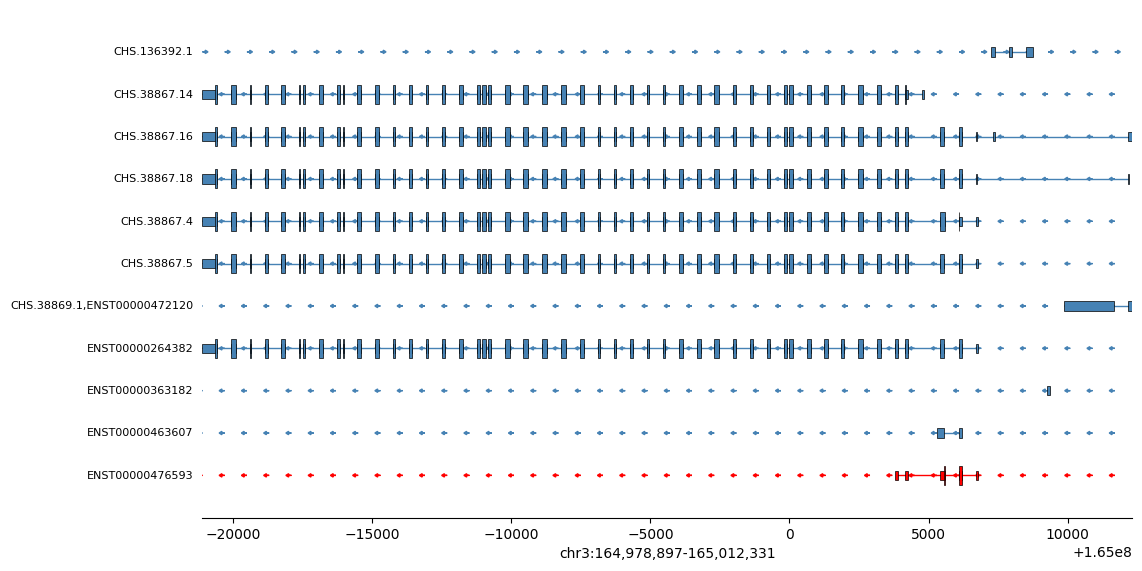

In [149]:
pg.plot_transcripts(df,gene_id=gid,collapse=True,highlight=highlight,resize_introns=500)

## Prepare data

### Our CHX (two samples, A549)

In [55]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/meta.csv')

In [56]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

In [57]:
getpsi = '../../../arkuda_backup/unproductive_splicing/data/TCGA/scripts/get_psi.py'
cmd = f"python {getpsi} -h"
!{cmd}

usage: get_psi.py [-h] -c C -j J [J ...] [-s S [S ...]] -o O [-t T]
                  [--step STEP] [--event EVENT [EVENT ...]]
                  [--groupcol GROUPCOL] [--numerator NUMERATOR]

options:
  -h, --help            show this help message and exit
  -c C                  path to catalog of junctions
  -j J [J ...]          pyIPSA J6 files
  -s S [S ...]          pyIPSA S6 files
  -o O                  output file
  -t T                  number of threads
  --step STEP           step to print info
  --event EVENT [EVENT ...]
                        colname(s) of event id
  --groupcol GROUPCOL   colname defining 2 groups for PSI calculation
  --numerator NUMERATOR
                        a group name in column "--groupcol" which will be
                        presented in numerator of PSI


In [58]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
cmd

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/psi already exists.


'python ../../../arkuda_backup/unproductive_splicing/data/TCGA/scripts/get_psi.py -c ./use_catalog/filtered_catalog.tsv -j ../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/pyIPSA/J6/*.J6.gz -s ../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/pyIPSA/S6/*.S6.gz -o ../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/psi/ensembl_chess.psi -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay'

In [59]:
!{cmd}

#-----starting parallel extraction of counts
0 columns processed, time since start: 1.7920112609863281
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.5800621509552002
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [60]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.7642159461975098
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.58146071434021
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [61]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/psi/ensembl_chess.psi',index_col=[0],comment='#',dtype=dtype)
psi['sample_id'] = psi['sample_id'].apply(lambda x: x.rpartition('_')[0])
df = meta[meta.condition.isin(['con','con_chx'])].rename(columns={'fname':'sample_id'}).merge(psi)
df['psi'] = df.num/df.denom
df = df.pivot(index=['src','event_id'],columns = 'condition', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.con_chx-df.psi.con
df = df[df.dpsi!=0].copy()

''

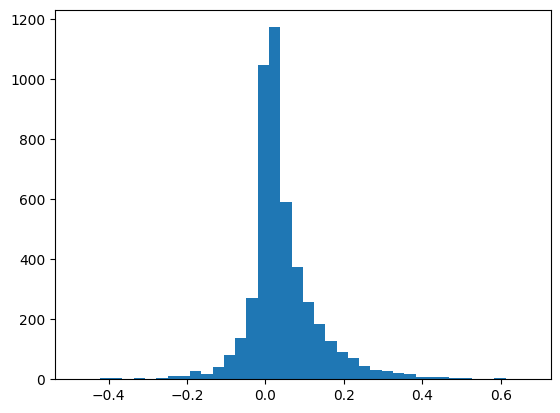

In [62]:
plt.hist(df.dpsi,bins=40)
''

In [63]:
d = {('psi', 'con'):'ctrl_psi',
 ('psi', 'con_chx'):'exp_psi',
 ('denom', 'con'):'ctrl_denom',
 ('denom', 'con_chx'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [64]:
!mkdir nmd_inactivation_data
df.to_csv('nmd_inactivation_data/rsf_chx.tsv',sep='\t',index=False)

A subdirectory or file nmd_inactivation_data already exists.


In [65]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/QKI_ILF2/psi/binASE.psi',index_col=[0],comment='#',dtype=dtype)
psi['sample_id'] = psi['sample_id'].apply(lambda x: x.rpartition('_')[0])
df = meta[meta.condition.isin(['con','con_chx'])].rename(columns={'fname':'sample_id'}).merge(psi)
df['psi'] = df.num/df.denom
df = df.pivot(index=['src','event_id'],columns = 'condition', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.con_chx-df.psi.con
df = df[df.dpsi!=0].copy()

''

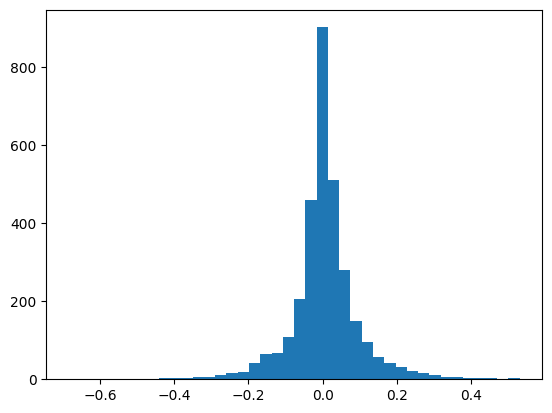

In [66]:
plt.hist(df.dpsi,bins=40)
''

In [67]:
d = {('psi', 'con'):'ctrl_psi',
 ('psi', 'con_chx'):'exp_psi',
 ('denom', 'con'):'ctrl_denom',
 ('denom', 'con_chx'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [68]:
df.to_csv('nmd_inactivation_data/rsf_chx_binASE.tsv',sep='\t',index=False)

### HeLa CHX and KDs: upf1, smg6, smg7

In [69]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
cmd

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi already exists.


'python ../../../arkuda_backup/unproductive_splicing/data/TCGA/scripts/get_psi.py -c ./use_catalog/filtered_catalog.tsv -j ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/J6/*.J6.gz -s ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/S6/*.S6.gz -o ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/ensembl_chess.psi -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay'

In [70]:
!{cmd}

#-----starting parallel extraction of counts
0 columns processed, time since start: 1.863318681716919
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.6023211479187012
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [71]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.8056097030639648
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.625767707824707
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [72]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)

In [73]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_all.tsv',sep='\t')
df = meta.merge(psi)
df = df.groupby(['group','experiment','src','event_id'],as_index=False,observed=True,sort=False)[['denom','num']].agg('mean')
df['psi'] = df.num/df.denom
df = df.pivot(index=['experiment','src','event_id'],columns = 'group', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.exp-df.psi.ctrl
df = df[df.dpsi!=0].copy()

In [74]:
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [75]:
df.experiment.value_counts()

experiment
HeLa_dKD        6554
HeLa_UPF1_KD    5259
HeLa_SMG6_KD    5109
HeLa_SMG7_KD    4985
Name: count, dtype: int64

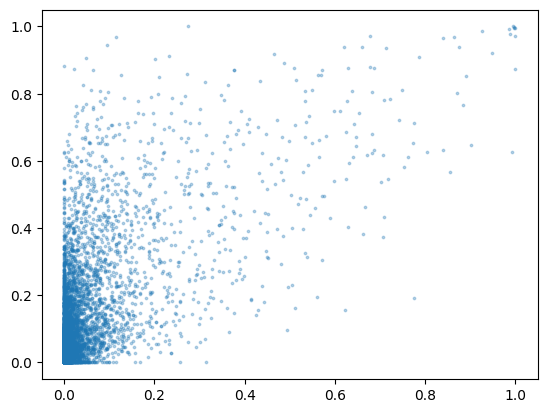

In [76]:
tmp = df[df.experiment=='HeLa_dKD']
plt.scatter(tmp.ctrl_psi,tmp.exp_psi,s=3,alpha=0.3)

In [77]:
df.to_csv('nmd_inactivation_data/hela_kd.tsv',sep='\t',index=False)

In [78]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)

In [79]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_all.tsv',sep='\t')
df = meta.merge(psi)
df = df.groupby(['group','experiment','src','event_id'],as_index=False,observed=True,sort=False)[['denom','num']].agg('mean')
df['psi'] = df.num/df.denom
df = df.pivot(index=['experiment','src','event_id'],columns = 'group', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.exp-df.psi.ctrl
df = df[df.dpsi!=0].copy()

In [80]:
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [81]:
df.experiment.value_counts()

experiment
HeLa_dKD        3411
HeLa_SMG7_KD    3299
HeLa_UPF1_KD    3180
HeLa_SMG6_KD    3104
Name: count, dtype: int64

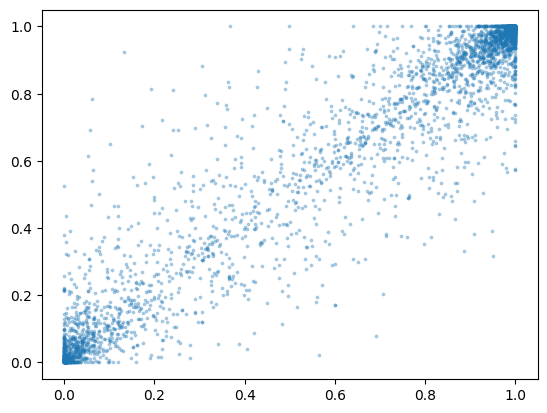

In [82]:
tmp = df[df.experiment=='HeLa_dKD']
plt.scatter(tmp.ctrl_psi,tmp.exp_psi,s=3,alpha=0.3)

In [83]:
df.to_csv('nmd_inactivation_data/hela_kd_binASE.tsv',sep='\t',index=False)

In [84]:
df.experiment.unique()

array(['HeLa_SMG6_KD', 'HeLa_SMG7_KD', 'HeLa_UPF1_KD', 'HeLa_dKD'],
      dtype=object)

### HeLa XRN1 and other (1 sample per group)

In [85]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.628082275390625
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.516702651977539
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [86]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.6767735481262207
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.5248239040374756
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [87]:
with open('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/GEO_metadata.txt','r') as f:
    meta = f.readlines()

meta = [i.strip() for i in meta]
res = []
curr = []
for line in meta:
    if line=='':
        res.append(curr.copy())
        curr = []
    elif (not line.isnumeric()) or (len(line)>2):
        curr.append(line)
if curr:
    res.append(curr)
meta = pd.DataFrame(res[1:],columns=res[0])

meta = meta[['Run','genotype/variation']].rename(columns={'Run':'sample_id'})
meta

,sample_id,genotype/variation
0,SRR1275413,control (EGFP siRNA-treated)
1,SRR1275414,XRN1 depletion
2,SRR1275415,SMG6/XRN1 depletion
3,SRR1275416,UPF1/XRN1 depletion


In [88]:
meta['experiment'] = ['ctrl','xrn1','xrn1_smg6','xrn1_upf1']
meta

,sample_id,genotype/variation,experiment
0,SRR1275413,control (EGFP siRNA-treated),ctrl
1,SRR1275414,XRN1 depletion,xrn1
2,SRR1275415,SMG6/XRN1 depletion,xrn1_smg6
3,SRR1275416,UPF1/XRN1 depletion,xrn1_upf1


In [89]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = df[(df.denom>15).copy()]

ctrl = df[df.experiment=='ctrl'][['src','event_id','psi','denom']].rename(columns={'psi':'ctrl_psi','denom':'ctrl_denom'})
df = df[df.experiment!='ctrl'][['src','event_id','experiment','psi','denom']].rename(columns={'psi':'exp_psi','denom':'exp_denom'})

df = df.merge(ctrl)
df = df[df.exp_psi!=df.ctrl_psi].copy()

In [90]:
df.experiment.unique()

array(['xrn1', 'xrn1_smg6', 'xrn1_upf1'], dtype=object)

In [91]:
df.to_csv('nmd_inactivation_data/xrn1.tsv',sep='\t',index=False)

In [92]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/XRN1_codepletion/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = df[(df.denom>15).copy()]

ctrl = df[df.experiment=='ctrl'][['src','event_id','psi','denom']].rename(columns={'psi':'ctrl_psi','denom':'ctrl_denom'})
df = df[df.experiment!='ctrl'][['src','event_id','experiment','psi','denom']].rename(columns={'psi':'exp_psi','denom':'exp_denom'})

df = df.merge(ctrl)
df = df[df.exp_psi!=df.ctrl_psi].copy()

''

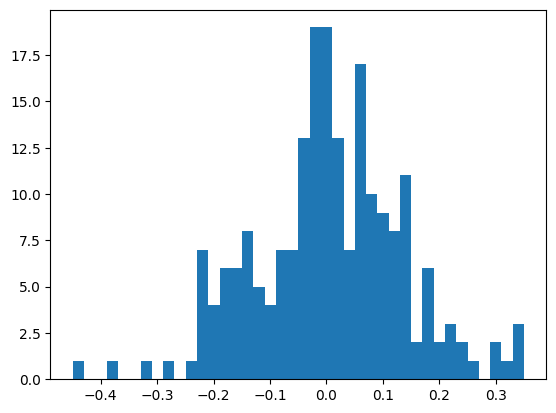

In [93]:
plt.hist(df.exp_psi-df.ctrl_psi,bins=40)
''

In [94]:
df.to_csv('nmd_inactivation_data/xrn1_binASE.tsv',sep='\t',index=False)

### CHX2

In [95]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.7725231647491455
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.5732505321502686
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [96]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.810246467590332
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.56380033493042
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [97]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/SraRunTable.txt')
cols = ['Run','cell_line','source_name','treatment']
meta = meta[meta.treatment.notna()][cols]
meta = meta[~meta.treatment.str.contains('SARS-CoV-2')]
meta['sample_type'] = np.where(meta.treatment.str.lower().str.contains('cycloheximide'),'chx','ctrl')
meta['experiment'] = np.where(meta.cell_line=='293T','293T_chx','iPS_organoids_chx')

meta = meta.rename(columns={'Run':'sample_id'})[['sample_id','experiment','sample_type']]

In [98]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','sample_type'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],columns='sample_type',values=['psi','denom'])

df = df[df.notna().all(1)].copy()
df = df[df.psi.chx!=df.psi.ctrl]

d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'chx'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'chx'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [99]:
df.experiment.unique()

array(['iPS_organoids_chx', '293T_chx'], dtype=object)

In [100]:
df.to_csv('nmd_inactivation_data/chx2.tsv',sep='\t',index=False)

In [101]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/CHX2/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','sample_type'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],columns='sample_type',values=['psi','denom'])

df = df[df.notna().all(1)].copy()
df = df[df.psi.chx!=df.psi.ctrl]

d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'chx'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'chx'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [102]:
df.to_csv('nmd_inactivation_data/chx2_binASE.tsv',sep='\t',index=False)

### RIPiT

In [103]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.8060407638549805
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.7154772281646729
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [104]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.8505728244781494
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.926070213317871
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [105]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/meta.csv')

In [106]:
res = []
for file in glob.glob('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/SraRu*'):
    aa = pd.read_csv(file)
    if 'BioProject' in aa.columns:
        cols = [i for i in aa.columns if 'cell_line' in i]
        res.append(aa[['Run','BioProject']+cols])
res = pd.concat(res)

In [107]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/meta.csv')

meta = meta[(meta['Assay Type']!='footprints')&
            (~meta.treatment.isin(['+ ligase (T4 Rnl 1\, NEB M0204S)','Harringtonine (2 ng/mL)\, one hour']))].copy()

meta['experiment'] = np.where(meta.treatment.isin(['control','CHX']),'hela_chx2','RIPiT')

meta['sample_type'] = np.where(meta.treatment.isin(['Untreated','control']),'ctrl','exp')
meta.loc[meta.time=='24 h','sample_type'] = 'exp2'

meta = meta.rename(columns={'Run':'sample_id'})[['sample_id','experiment','sample_type']]

In [108]:
samples = meta[meta.experiment=='RIPiT'].sample_id
paths = [f'/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/{sample}/Aligned.sortedByCoord.out.bam' for sample in samples]
'("'+'" "'.join(paths)+'")'

'("/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340370/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340371/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340372/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340373/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340374/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340375/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340376/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340377/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340378/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340379/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR7340380/Aligned.sortedByCoord.out.bam" "/gss/dp

In [109]:
samples = meta[meta.experiment=='hela_chx2'].sample_id
paths = [f'/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/{sample}/Aligned.sortedByCoord.out.bam' for sample in samples]
'("'+'" "'.join(paths)+'")'

'("/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443314/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443315/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443316/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443317/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443318/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443319/Aligned.sortedByCoord.out.bam")'

In [110]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','sample_type'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],columns='sample_type',values=['psi','denom'])

df1 = df[(df.psi[['ctrl','exp']].notna().all(1))&(df.psi.ctrl!=df.psi.exp)].drop([('psi','exp2'),('denom','exp2')],axis=1)
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df1.columns = df1.columns.map(d)
df1 = df1[d.values()].reset_index().copy()
df1.experiment = df1.experiment.replace('hela_chx2','hela_chx_15min')

df2 = df[(df.psi[['ctrl','exp2']].notna().all(1))&(df.psi.ctrl!=df.psi.exp2)].drop([('psi','exp'),('denom','exp')],axis=1)
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp2'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp2'):'exp_denom'}

df2.columns = df2.columns.map(d)
df2 = df2[d.values()].reset_index().copy()
df2.experiment = df2.experiment.replace('hela_chx2','hela_chx_24h')

df = pd.concat([df1,df2])

In [111]:
df.experiment.unique()

array(['RIPiT', 'hela_chx_15min', 'hela_chx_24h'], dtype=object)

In [112]:
df.to_csv('nmd_inactivation_data/ripit_and_chx.tsv',sep='\t',index=False)

In [113]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','sample_type'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],columns='sample_type',values=['psi','denom'])

df1 = df[(df.psi[['ctrl','exp']].notna().all(1))&(df.psi.ctrl!=df.psi.exp)].drop([('psi','exp2'),('denom','exp2')],axis=1)
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df1.columns = df1.columns.map(d)
df1 = df1[d.values()].reset_index().copy()
df1.experiment = df1.experiment.replace('hela_chx2','hela_chx_15min')

df2 = df[(df.psi[['ctrl','exp2']].notna().all(1))&(df.psi.ctrl!=df.psi.exp2)].drop([('psi','exp'),('denom','exp')],axis=1)
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp2'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp2'):'exp_denom'}

df2.columns = df2.columns.map(d)
df2 = df2[d.values()].reset_index().copy()
df2.experiment = df2.experiment.replace('hela_chx2','hela_chx_24h')

df = pd.concat([df1,df2])

In [114]:
df.to_csv('nmd_inactivation_data/ripit_and_chx_binASE.tsv',sep='\t',index=False)

In [115]:
df['dpsi'] = df.exp_psi-df.ctrl_psi

In [116]:
df.groupby('experiment').dpsi.describe()

,count,mean,std,min,25%,50%,75%,max
experiment,,,,,,,,
RIPiT,884.0,0.006026,0.072605,-0.457458,-0.014973,0.004411,0.028436,0.428148
hela_chx_15min,627.0,0.001256,0.103334,-0.402972,-0.052653,0.003576,0.052699,0.406546
hela_chx_24h,769.0,-0.001692,0.120082,-0.457002,-0.059524,-0.001504,0.055195,0.646944


In [117]:
aa = df.pivot(index=['src','event_id'],columns='experiment',values='dpsi')
aa.corr()

experiment,RIPiT,hela_chx_15min,hela_chx_24h
experiment,,,
RIPiT,1.000000,-0.132890,0.185487
hela_chx_15min,-0.132890,1.000000,0.302503
hela_chx_24h,0.185487,0.302503,1.000000


<Axes: xlabel='dpsi', ylabel='Density'>

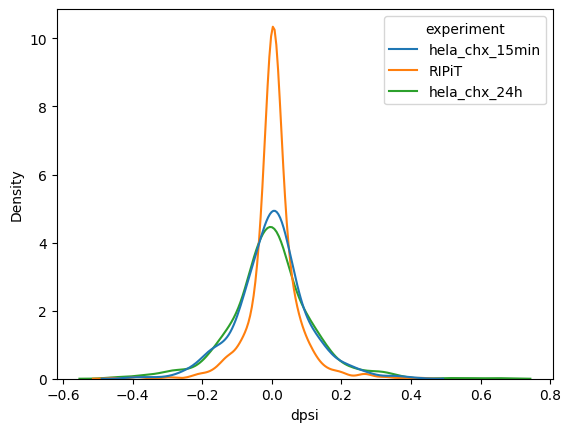

In [118]:
sns.kdeplot(data=df,x='dpsi',hue='experiment',common_norm=False)

#### Gene exonic counts

In [119]:
!wsl cp -r "../nmd_inactivation_data/gene_counts" "./nmd_inactivation_data/"

In [120]:
!wsl cp -r "../nmd_inactivation_data/deseq_res" "./nmd_inactivation_data/"

In [121]:
df = pd.read_csv('./nmd_inactivation_data/gene_counts/ripit.txt',sep='\t',comment='#')

df['gene_id'] = df.Geneid.apply(lambda x: x.split('.')[0])
df = df.drop(['Geneid','Chr','Start','End','Strand','Length'],axis=1)

In [122]:
df = df.groupby('gene_id').agg('sum')

In [123]:
df.columns = [os.path.basename(os.path.dirname(i)) for i in df.columns]

In [124]:
aa = df.min(axis=1)

In [125]:
aa = (df.quantile(0.2,axis=1)>10)
df = df.loc[aa]

In [126]:
def get_sf(expr,pseudo=1):
    ref = np.log(expr).apply(np.mean,1).apply(np.exp)
    sf = expr.div(ref,axis=0).apply(np.median)
    return sf

sf = get_sf(df)
expr = df.div(sf)

In [127]:
sf

SRR7340370     0.286037
SRR7340371     0.279588
SRR7340372     0.320022
SRR7340373     0.322187
SRR7340374     0.425120
SRR7340375     0.419885
SRR7340376     0.468324
SRR7340377     0.476124
SRR7340378     0.401238
SRR7340379     0.392787
SRR7340380     0.443538
SRR11746990    5.444463
SRR11746991    7.403493
SRR11746992    4.164996
SRR11746993    6.738690
SRR11746994    6.097881
SRR11746995    6.931108
dtype: float64

In [128]:
expr = expr.reset_index().melt(id_vars='gene_id',var_name='sample_id',value_name='expr')

In [129]:
lfc = meta.merge(expr).groupby(['experiment','sample_type','gene_id'],as_index=False).expr.agg('mean')
lfc = lfc.pivot(index=['experiment','gene_id'],columns='sample_type',values='expr')
lfc = lfc[(lfc.ctrl>10)&(lfc.exp>10)]
lfc['logFC']  = np.log2(lfc.exp/lfc.ctrl)

In [130]:
lfc.reset_index().to_csv('./nmd_inactivation_data/deseq_res/ripit_gene_logFC.tsv',sep='\t',index=False)

#### HeLa chx (24h) logFC

In [131]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/meta.csv')

meta = meta[(meta['Assay Type']!='footprints')&
            (~meta.treatment.isin(['+ ligase (T4 Rnl 1\, NEB M0204S)','Harringtonine (2 ng/mL)\, one hour']))].copy()

meta['experiment'] = np.where(meta.treatment.isin(['control','CHX']),'hela_chx2','RIPiT')

meta['sample_type'] = np.where(meta.treatment.isin(['Untreated','control']),'ctrl','exp')
meta.loc[meta.time=='24 h','sample_type'] = 'exp2'

meta = meta.rename(columns={'Run':'sample_id'})[['sample_id','experiment','sample_type']]

In [132]:
df = pd.read_csv('./nmd_inactivation_data/gene_counts/hela_chx.txt',sep='\t',comment='#')

df['gene_id'] = df.Geneid.apply(lambda x: x.split('.')[0])
df = df.drop(['Geneid','Chr','Start','End','Strand','Length'],axis=1)

In [133]:
df = df.groupby('gene_id').agg('sum')

In [134]:
df.columns = [os.path.basename(os.path.dirname(i)) for i in df.columns]

In [135]:
aa = df.min(axis=1)

In [136]:
aa = (df.quantile(0.2,axis=1)>10)
df = df.loc[aa]

In [137]:
def get_sf(expr,pseudo=1):
    ref = np.log(expr).apply(np.mean,1).apply(np.exp)
    sf = expr.div(ref,axis=0).apply(np.median)
    return sf

sf = get_sf(df)
expr = df.div(sf)

In [138]:
sf

SRR8443314    1.056298
SRR8443315    0.900269
SRR8443316    0.919712
SRR8443317    0.914250
SRR8443318    1.134793
SRR8443319    1.116140
dtype: float64

In [139]:
expr = expr.reset_index().melt(id_vars='gene_id',var_name='sample_id',value_name='expr')

In [140]:
expr

,gene_id,sample_id,expr
0,ENSG00000000003,SRR8443314,508.379132
1,ENSG00000000419,SRR8443314,990.250599
2,ENSG00000000457,SRR8443314,237.622276
3,ENSG00000000460,SRR8443314,537.726903
4,ENSG00000001036,SRR8443314,2095.998878
...,...,...,...
75535,ENSG00000291223,SRR8443319,60.028323
75536,ENSG00000291224,SRR8443319,49.276981
75537,ENSG00000291228,SRR8443319,108.409359
75538,ENSG00000291234,SRR8443319,72.571554


In [141]:
lfc = meta[meta.experiment=='hela_chx2'].merge(expr).groupby(['sample_type','gene_id'],as_index=False).expr.agg('mean')
lfc = lfc.pivot(index=['gene_id'],columns='sample_type',values='expr')

In [142]:
lfc = lfc[(lfc.ctrl>10)&(lfc.exp2>10)].copy()
lfc['log2FoldChange']  = np.log2(lfc.exp2/lfc.ctrl)

In [143]:
aa = lfc[['log2FoldChange']]
aa = aa.reset_index()
aa

sample_type,gene_id,log2FoldChange
0,ENSG00000000003,-1.201393
1,ENSG00000000419,1.076415
2,ENSG00000000457,1.433791
3,ENSG00000000460,1.583727
4,ENSG00000001036,-1.362895
...,...,...
12411,ENSG00000291223,-0.363588
12412,ENSG00000291224,-0.149568
12413,ENSG00000291228,1.475069
12414,ENSG00000291234,-0.246220


In [144]:
aa.to_csv('./nmd_inactivation_data/deseq_res/HeLa_chx.tsv',sep='\t',index=False)

### Nuclear-cytosolic fractioning

In [145]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 10 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 3.2232022285461426
#-----starting parallel extraction of counts
0 columns processed, time since start: 3.027139902114868
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [146]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 10 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 2.7705886363983154
#-----starting parallel extraction of counts
0 columns processed, time since start: 2.480517864227295
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [147]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed.csv').rename(columns={'fname':'sample_id'}).drop('replicate',axis=1)

In [148]:
meta['experiment'] = 'fractioning_'+meta.cell_line

In [149]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','cellular_component'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],
                                         columns='cellular_component',values=['psi','denom'])

df = df[df.notna().all(1)].copy()
df = df[df.psi.cytosol!=df.psi.nucleus]

d = {('psi', 'cytosol'):'ctrl_psi',
 ('psi', 'nucleus'):'exp_psi',
 ('denom', 'cytosol'):'ctrl_denom',
 ('denom', 'nucleus'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [150]:
df.to_csv('nmd_inactivation_data/fractioning.tsv',sep='\t',index=False)

In [151]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','cellular_component'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],
                                         columns='cellular_component',values=['psi','denom'])

df = df[df.notna().all(1)].copy()
df = df[df.psi.cytosol!=df.psi.nucleus]

d = {('psi', 'cytosol'):'ctrl_psi',
 ('psi', 'nucleus'):'exp_psi',
 ('denom', 'cytosol'):'ctrl_denom',
 ('denom', 'nucleus'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [152]:
df.to_csv('nmd_inactivation_data/fractioning_binASE.tsv',sep='\t',index=False)

#### QC

In [153]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df)

In [154]:
df = df[df.denom>15]

In [155]:
df = df.pivot(index=['sample_id'],columns=['src','event_id'],values='psi')

In [156]:
aa = df.isna().sum()
bb = aa.value_counts()
bb = bb.loc[sorted(bb.index)]

<BarContainer object of 66 artists>

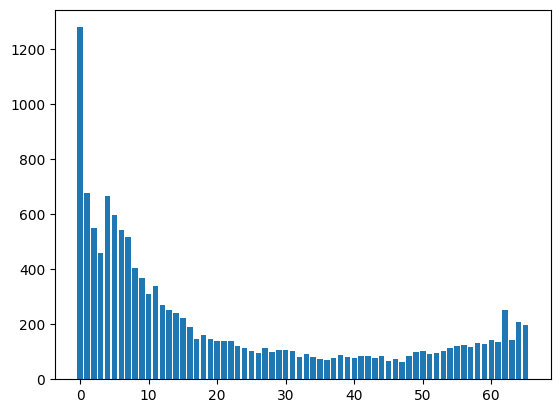

In [157]:
plt.bar(bb.index,bb)

In [158]:
ind = aa[aa==0].index
bb = df.std()
ind2 = bb[bb>0].index
mat = df[ind.intersection(ind2)].apply(lambda x: (x-np.mean(x))/np.std(x))

In [159]:
from sklearn.decomposition import PCA

sk_pca = PCA()
sk_X_transformed = sk_pca.fit_transform(mat)

pc = pd.DataFrame(sk_X_transformed)[[0,1,2]]
pc.index = mat.index

pc = pc.reset_index()

In [160]:
pc = meta.merge(pc)

In [161]:
pc['group'] = pc['cellular_component']
pc.experiment = pc.cell_line

In [162]:
pc.experiment = pc.experiment.replace('endothelial cell of umbilical vein','vein')

Text(0, 0.5, 'PC2 (7% variance)')

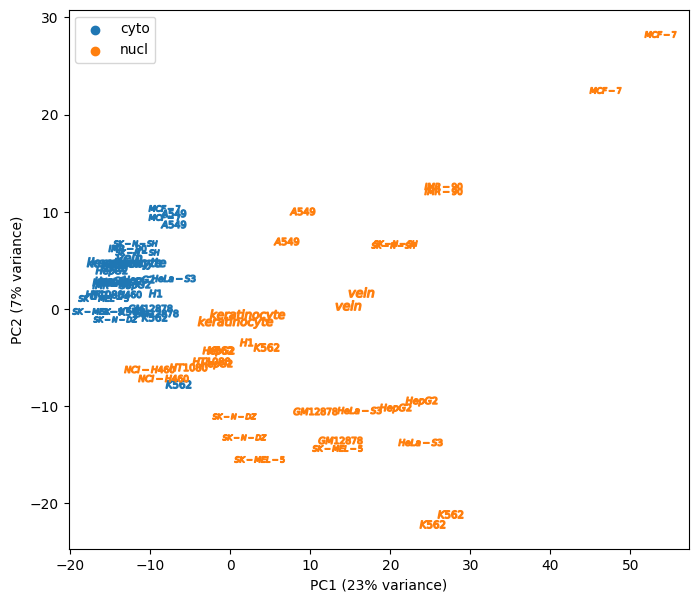

In [163]:
from adjustText import adjust_text
f,ax = plt.subplots(figsize=(8,7))
s=20
texts = []
cmap = plt.get_cmap('tab10')
grpal = {'cytosol':cmap(0),'nucleus':cmap(1)}
for key, tmp in pc.groupby(['experiment','group']):
    ax.scatter(tmp[0],tmp[1],marker=f"${key[0]}$",color=grpal[key[1]],s=s*len(key[0])**2)

xl = ax.get_xlim()
yl = ax.get_ylim()
ax.scatter(10000,10000,color=grpal['cytosol'],label='cyto')
ax.scatter(10000,10000,color=grpal['nucleus'],label='nucl')
ax.legend()

ax.set_xlim(*xl)
ax.set_ylim(*yl)

expvar = np.round(sk_pca.explained_variance_ratio_*100)
ax.set_xlabel(f'PC1 ({int(expvar[0])}% variance)')
ax.set_ylabel(f'PC2 ({int(expvar[1])}% variance)')

In [164]:
samples = meta.groupby('cellular_component').sample_id.agg(list)

In [165]:
from sklearn.decomposition import PCA
mat1 = mat.loc[samples.nucleus]

sk_pca = PCA()
sk_X_transformed = sk_pca.fit_transform(mat1)

pc = pd.DataFrame(sk_X_transformed)[[0,1,2]]
pc.index = mat1.index

pc = pc.reset_index()
pc = meta.merge(pc)

In [166]:
pc['group'] = pc['cellular_component']
pc.experiment = pc.cell_line

In [167]:
pc.experiment = pc.experiment.replace('endothelial cell of umbilical vein','vein')

Text(0, 0.5, 'PC2 (10% variance)')

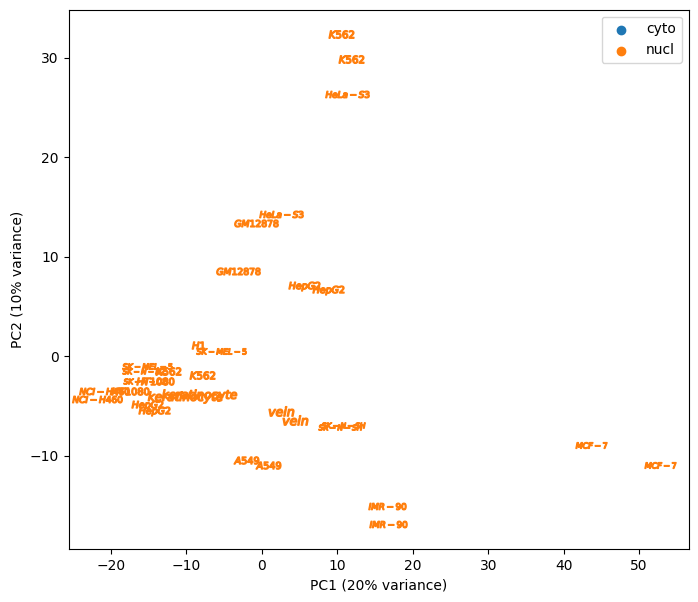

In [168]:
from adjustText import adjust_text
f,ax = plt.subplots(figsize=(8,7))
s=20
texts = []
cmap = plt.get_cmap('tab10')
grpal = {'cytosol':cmap(0),'nucleus':cmap(1)}
for key, tmp in pc.groupby(['experiment','group']):
    ax.scatter(tmp[0],tmp[1],marker=f"${key[0]}$",color=grpal[key[1]],s=s*len(key[0])**2)

xl = ax.get_xlim()
yl = ax.get_ylim()
ax.scatter(10000,10000,color=grpal['cytosol'],label='cyto')
ax.scatter(10000,10000,color=grpal['nucleus'],label='nucl')
ax.legend()

ax.set_xlim(*xl)
ax.set_ylim(*yl)

expvar = np.round(sk_pca.explained_variance_ratio_*100)
ax.set_xlabel(f'PC1 ({int(expvar[0])}% variance)')
ax.set_ylabel(f'PC2 ({int(expvar[1])}% variance)')

In [169]:
from scipy.spatial.distance import pdist
from itertools import combinations

coords = pc[[0,1]].to_numpy()
dist = pd.DataFrame(list(combinations(pc.sample_id,2)),columns=['sample1','sample2'])
dist['dist'] = pdist(coords)

In [170]:
aa = pc[['sample_id','experiment','group']].copy()
aa.columns = ['sample1','e1','g1']
bb = pc[['sample_id','experiment','group']].copy()
bb.columns = ['sample2','e2','g2']
dist = dist.merge(aa).merge(bb)

In [171]:
condition = (dist.e1==dist.e2)&(dist.g1==dist.g2)
dist['is_replicate'] = condition.astype(int)
aa = dist[dist.g1==dist.g2].groupby(['e1','g1','is_replicate']).dist.agg('mean').reset_index()
aa.head()

,e1,g1,is_replicate,dist
0,A549,nucleus,0,20.605790
1,A549,nucleus,1,3.034053
2,GM12878,nucleus,0,21.435854
3,GM12878,nucleus,1,5.333706
4,H1,nucleus,0,18.076830


In [172]:
aa.pivot(index=['e1','g1'],columns='is_replicate',values='dist')

,is_replicate,0,1
e1,g1,,
A549,nucleus,20.605790,3.034053
GM12878,nucleus,21.435854,5.333706
H1,nucleus,18.076830,NaN
HT1080,nucleus,21.300515,3.499618
HeLa-S3,nucleus,29.807983,14.918143
HepG2,nucleus,22.448692,17.437684
IMR-90,nucleus,30.299364,1.793424
K562,nucleus,30.043514,27.355038
MCF-7,nucleus,55.649948,9.391369


#### Expression

In [173]:
file = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed.csv'
meta = pd.read_csv(file)
meta = meta.rename(columns={'fname':'sample_id'}).drop('replicate',axis=1)

In [174]:
pe = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed-PE.csv'
se = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed-SE.csv'
pe = pd.read_csv(pe)
se = pd.read_csv(se)

In [175]:
pe_samples = set(pe.dbxrefs)
se_samples = set(se.dbxrefs)
all_samples = set(meta.sample_id)

In [176]:
se

,File accession,Experiment accession,Biosample term name,Run type,Biological replicate(s),dbxrefs
0,ENCFF000LSY,ENCSR000BZV,K562,single-ended,1,SRR5210711


In [177]:
pe_samples&se_samples

set()

In [178]:
all_samples-(pe_samples|se_samples)

set()

In [179]:
all_samples==(pe_samples|se_samples)

True

In [180]:
def mask(sample):
    return f'"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/{sample}/Aligned.sortedByCoord.out.bam"'
files  = [mask(i) for i in pe_samples]

In [181]:
print('files=(')
print('\n'.join(files))
print(')')

files=(
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR5048146/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192637/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192546/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192485/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR5048152/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192627/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR4422653/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR4421919/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCO

#### logFC

In [182]:
df = pd.read_csv('./nmd_inactivation_data/gene_counts/fractioning.txt',sep='\t',comment='#')

df['gene_id'] = df.Geneid.apply(lambda x: x.split('.')[0])
df = df.drop(['Geneid','Chr','Start','End','Strand','Length'],axis=1)

In [183]:
df = df.groupby('gene_id').agg('sum')

In [184]:
df.columns = [os.path.basename(os.path.dirname(i)) for i in df.columns]

In [185]:
def get_sf(expr,pseudo=1):
    ref = np.log(expr).apply(np.mean,1).apply(np.exp)
    sf = expr.div(ref,axis=0).apply(np.median)
    return sf

In [186]:
def get_lfc(x,meta):
    df = x.copy()
    cols = df.columns.intersection(meta.sample_id.unique())
    df = df[cols]
    df = df[(df>10).all(1)]
    print(f'#genes = {len(df)}')
    sf = get_sf(df)
    expr = df.div(sf)
    samples = meta[meta.sample_id.isin(cols)].groupby('cellular_component').sample_id.agg(list)
    exper = expr[samples.nucleus].mean(axis=1)
    ctrl = expr[samples.cytosol].mean(axis=1)
    print('SF:', sf.tolist())
    lfc = np.log2(exper/ctrl)
    lfc = lfc.reset_index()
    lfc.columns=['gene_id','log2FoldChange']
    return lfc

In [187]:
res = []
for key,submeta in meta.groupby('cell_line'):
    print(key)
    lfc = get_lfc(df,submeta)
    lfc['experiment'] = f'fractioning_{key}'
    res.append(lfc)

A549
#genes = 17512
SF: [0.8465648449027543, 1.335940429094458, 0.8650713093559586, 1.0393262101914318]
GM12878
#genes = 17626
SF: [1.1731592651393294, 0.9036054594298675, 0.7312126062690086, 1.298131653486346]
H1
#genes = 21397
SF: [0.9512031960481078, 1.0513000840983546]
HT1080
#genes = 15169
SF: [0.9442809149528018, 1.048131819265993, 1.1354036893675927, 0.9105927280067191]
HeLa-S3
#genes = 15141
SF: [1.3065345442077312, 0.9166114604822057, 0.8693416192281014, 0.9637480425690745]
HepG2
#genes = 11566
SF: [0.8561315776379916, 0.3147419061335661, 0.814262500371751, 1.772161732657052, 1.7839711265462825, 1.611634842648865, 0.3978574683429166, 2.155999849857528]
IMR-90
#genes = 14223
SF: [1.1976915619289192, 0.6036643313489151, 2.0813669706653033, 0.6753574743662182]
K562
#genes = 12503
SF: [1.0535809366322018, 1.6326710484104443, 1.1089073489205197, 1.817721748502542, 0.42141893527015106, 1.534681194753322, 0.43099350170918305, 0.9990883073029094]
MCF-7
#genes = 17727
SF: [1.1947558506

In [188]:
res = pd.concat(res)

In [189]:
res.to_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t',index=False)

### Master-table

In [40]:
use = []
ase = []
for file in glob.glob('./nmd_inactivation_data/*.tsv'):
    if ('master_table' in file) or ('bootstrapping' in file):
        continue
    name = os.path.basename(file)[:-4]
    aa = pd.read_csv(file,sep='\t')
    if 'experiment' not in aa.columns:
        print(name)
        name2 = name.replace('_binASE','')
        aa['experiment'] = name2
    aa['file'] = name
    if 'binASE' in file:
        ase.append(aa)   
    else:
        use.append(aa)
ase = pd.concat(ase)
use = pd.concat(use)

rsf_chx
rsf_chx_binASE


In [41]:
use.experiment.unique()

array(['iPS_organoids_chx', '293T_chx', 'fractioning_A549',
       'fractioning_H1', 'fractioning_HT1080', 'fractioning_HepG2',
       'fractioning_IMR-90', 'fractioning_K562', 'fractioning_GM12878',
       'fractioning_HeLa-S3', 'fractioning_MCF-7', 'fractioning_NCI-H460',
       'fractioning_SK-N-DZ', 'fractioning_SK-N-SH',
       'fractioning_endothelial cell of umbilical vein',
       'fractioning_keratinocyte', 'fractioning_SK-MEL-5', 'HeLa_SMG6_KD',
       'HeLa_SMG7_KD', 'HeLa_UPF1_KD', 'HeLa_dKD', 'RIPiT',
       'hela_chx_15min', 'hela_chx_24h', 'rsf_chx', 'xrn1', 'xrn1_smg6',
       'xrn1_upf1'], dtype=object)

In [42]:
use.experiment = use.experiment.replace('hela_chx_24h','HeLa_chx')
ase.experiment = ase.experiment.replace('hela_chx_24h','HeLa_chx')

In [43]:
use = use[(use.ctrl_psi!=0)&(use.exp_psi!=0)].copy()
ase = ase[(ase.ctrl_psi!=0)&(ase.exp_psi!=0)].copy()

In [44]:
def replace(x):
    frac = 'nucl/cyto'
    xr = x.str.replace('_',' ').str.replace('fractioning',frac).str.replace('chx','CHX')
    cond = xr.str.contains(frac)
    xr.loc[cond] = xr.loc[cond].apply(lambda x: ' '.join(x.split(' ')[::-1]))
    return xr
use.experiment = replace(use.experiment)
ase.experiment = replace(ase.experiment)

In [45]:
set(use.experiment)-set(ase.experiment),set(ase.experiment)-set(use.experiment)

(set(), set())

''

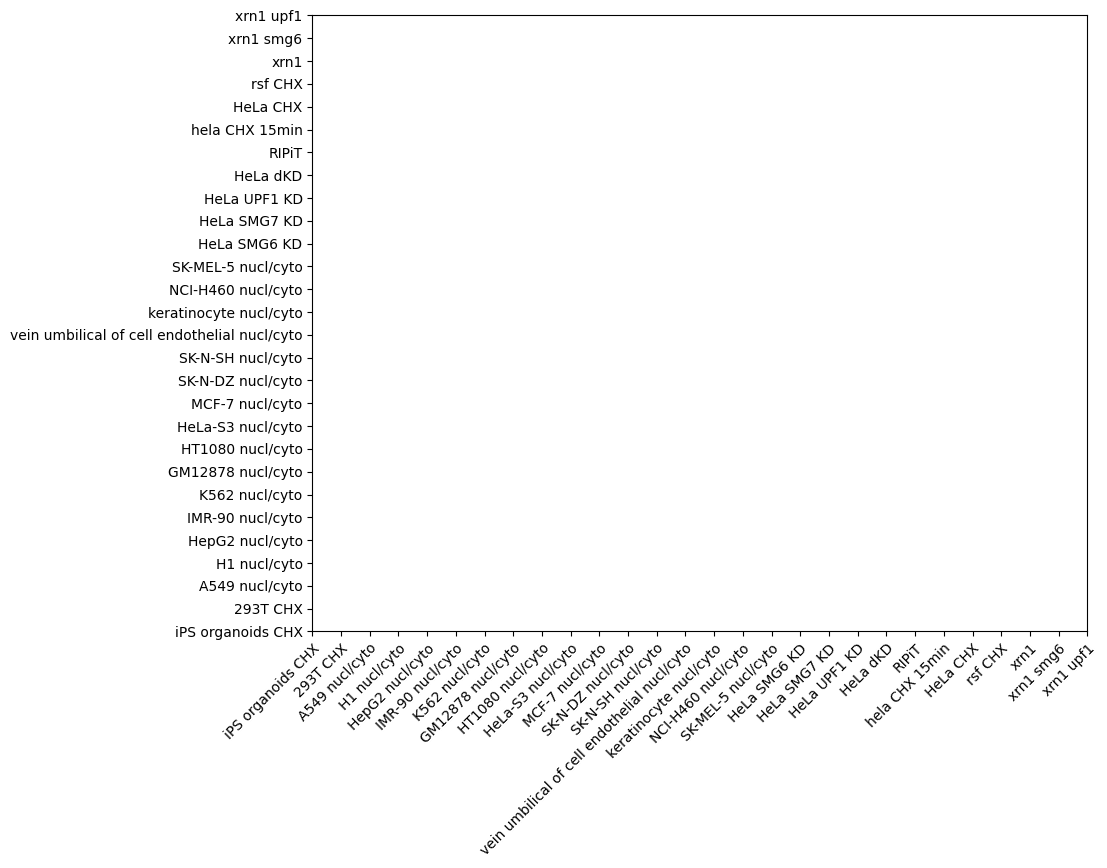

In [46]:
f,ax = plt.subplots(figsize=(10,8))

lst = use.experiment.unique()
x = list(range(len(lst)))
ax.set_yticks(x,labels=lst)
ax.set_xticks(x,labels=lst,rotation=45,rotation_mode='anchor',ha='right')
''

In [47]:
assert all(use[['experiment','file']].drop_duplicates().experiment.value_counts()==1)

In [48]:
assert all(ase[['experiment','file']].drop_duplicates().experiment.value_counts()==1)

In [49]:
use.to_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t',index=False)
ase.to_csv('./nmd_inactivation_data/binASE_master_table.tsv',sep='\t',index=False)

In [197]:
use.experiment.unique()

array(['iPS_organoids_chx', '293T_chx', 'fractioning_A549',
       'fractioning_H1', 'fractioning_HT1080', 'fractioning_HepG2',
       'fractioning_IMR-90', 'fractioning_K562', 'fractioning_GM12878',
       'fractioning_HeLa-S3', 'fractioning_MCF-7', 'fractioning_NCI-H460',
       'fractioning_SK-N-DZ', 'fractioning_SK-N-SH',
       'fractioning_endothelial cell of umbilical vein',
       'fractioning_keratinocyte', 'fractioning_SK-MEL-5', 'HeLa_SMG6_KD',
       'HeLa_SMG7_KD', 'HeLa_UPF1_KD', 'HeLa_dKD', 'RIPiT',
       'hela_chx_15min', 'HeLa_chx', 'rsf_chx', 'xrn1', 'xrn1_smg6',
       'xrn1_upf1'], dtype=object)

## USE subsets

### Set1 (events from literature) - ST1

In [250]:
set1 = pd.read_csv('./tables/lev_ST1.tsv',sep='\t')

In [251]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

In [252]:
oldcat = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/nmdj.tsv',sep='\t')
oldcat['src'] = 'nmdj_anno'

In [253]:
old = oldcat[oldcat.transcript_biotype=='nonsense_mediated_decay'].groupby(['src','event_id','gene_id'], 
                                                                           observed=True,sort=False).long_id.agg(set).reset_index()
old.columns = ['old_src','old_id','gene_id','old_set']

new = catalog[catalog.transcript_biotype=='nonsense_mediated_decay'].groupby(['src','event_id','gene_id'],
                                                                             observed=True,
                                                                             sort=False).long_id.agg(set).reset_index()
new.columns = ['new_src','new_id','gene_id','new_set']

In [254]:
mapping = old.merge(new)

In [255]:
mapping['n_old'] = mapping.old_set.map(len)
mapping['n_new'] = mapping.new_set.map(len)
mapping['n_common'] = mapping.apply(lambda x: len(x.old_set&x.new_set),axis=1)

In [256]:
mapping[mapping.n_common!=0].groupby(['old_src','old_id']).size().value_counts()

1    10803
2       25
4        1
3        1
Name: count, dtype: int64

In [257]:
mapping = mapping[mapping.n_common>0].sort_values('n_common',ascending=False).drop_duplicates(['old_src','old_id'])

In [258]:
needmap = set1[set1['from'] == 'literature'].drop_duplicates('event_id').set_index('event_id')[['gene_name','pmid']]
aa = mapping.set_index('old_id')[['new_src','new_id']]
aa.columns = ['src','event_id']
ind = needmap.index.intersection(aa.index)
lit = pd.concat([aa.loc[ind],needmap.loc[ind]],axis=1).reset_index(drop=True)
lit.loc[lit.gene_name.isin(['DCLK2','IQGAP1']),'pmid'] = '36912101'

In [259]:
set1['from'].unique()

array(['Alexey', 'fallout', 'literature', 'olgaA', 'our'], dtype=object)

In [260]:
other = set1[set1['from'].isin(['Alexey','olgaA'])][['gene_name','event_id','event_type','pmid']].copy()
other.event_type = other.event_type.apply(lambda x: x.split('/')[-1])
other = other.apply(lambda x: x.str.strip())
other = other.merge(cat,how='left')
other = other[other.event_id.notna()].sort_values(['src','event_id']).drop_duplicates().reset_index(drop=True)
other = other[lit.columns]
other

,src,event_id,gene_name,pmid
0,chess,ENSG00000011304_0,PTBP1,"17679092, 14731397, 27808105"
1,chess,ENSG00000101442_1,ACTR5,24567363
2,chess,ENSG00000116560_0,SFPQ,30916337
3,chess,ENSG00000122566_0,HNRNPA2B1,"23863836, 20946641"
4,chess,ENSG00000136450_0,SRSF1,33176162
5,chess,ENSG00000143889_0,HNRNPLL,"19124611, 18073345"
6,chess,ENSG00000198625_0,MDM4,26595814
7,chess,ENSG00000263465_0,SRSF8,33176162
8,ensembl,ENSG00000100316_0,RPL3,16254077
9,ensembl,ENSG00000100320_0,RBFOX2,21747913


In [274]:
st1 = pd.concat([lit,other])
st1.pmid = st1.pmid.str.split(', ').apply(set)
st1 = st1.groupby(['gene_name',
                   'src','event_id']).pmid.agg(lambda x: set.union(*x)).apply(lambda x: ', '.join(sorted(x)))
st1 = st1.reset_index()

In [275]:
intl = catalog[catalog.transcript_biotype=='nonsense_mediated_decay'][['src','event_id','event_type',
                                                                       'long_id']].merge(st1[['src','event_id']])
intl['chrom'] = intl.long_id.apply(lambda x: x.split('_')[0])
intl['strand'] = intl.long_id.apply(lambda x: x.split('_')[-1])
intl['coord'] = intl.long_id.apply(lambda x: set(map(int,x.split('_')[1:-1])))

intl = intl.groupby(['src','event_id','event_type','chrom','strand'],as_index=False).coord.agg(lambda x: set.union(*x))
intl['start'] = intl.coord.map(min)
intl['end'] = intl.coord.map(max)

In [276]:
cols = ['gene_name', 'src', 'event_id', 'event_type', 'chrom', 'start',
       'end', 'strand', 'pmid']
st1 = st1.merge(intl.drop('coord',axis=1))[cols]

In [278]:
st1.to_csv('./tables/ST1.tsv',sep='\t',index=False)

In [2]:
st1 = pd.read_csv('./tables/ST1.tsv',sep='\t')

In [4]:
st1.shape

(35, 9)

#### Old

In [38]:
#qpcr and dp files came from google drive 

catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
geneid = pd.read_csv('../../../arkuda_backup/gtfs/geneid.csv')
qpcr = pd.read_csv('../nmd_kd_experimental/ALL qPCR 2024-2026 - KD+OE.csv')
dp = pd.read_csv('../nmd_kd_experimental/мишени чувствительность к NMD - Лист1.csv')

In [39]:
oldcat = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/nmdj.tsv',sep='\t')
oldcat['src'] = 'nmdj_anno'

In [40]:
old = oldcat[oldcat.transcript_biotype=='nonsense_mediated_decay'].groupby(['src','event_id','gene_id'], 
                                                                           observed=True,sort=False).long_id.agg(set).reset_index()
old.columns = ['old_src','old_id','gene_id','old_set']

new = catalog[catalog.transcript_biotype=='nonsense_mediated_decay'].groupby(['src','event_id','gene_id'],
                                                                             observed=True,
                                                                             sort=False).long_id.agg(set).reset_index()
new.columns = ['new_src','new_id','gene_id','new_set']

In [41]:
mapping = old.merge(new)

In [42]:
mapping['n_old'] = mapping.old_set.map(len)
mapping['n_new'] = mapping.new_set.map(len)
mapping['n_common'] = mapping.apply(lambda x: len(x.old_set&x.new_set),axis=1)

In [43]:
mapping[mapping.n_common!=0].groupby(['old_src','old_id']).size().value_counts()

1    10803
2       25
4        1
3        1
Name: count, dtype: int64

In [44]:
mapping = mapping[mapping.n_common>0].sort_values('n_common',ascending=False).drop_duplicates(['old_src','old_id'])

In [45]:
qp = pd.read_csv('../nmd_kd_experimental/ALL qPCR 2024-2026 - KD+OE_nmd_dpsi.csv',index_col=[0])

In [46]:
valid = pd.read_csv('../nmd_kd_experimental/validated_USEs_our_lab&lit.csv')

In [47]:
mapping = mapping[['old_src','old_id','new_src','new_id']]

In [48]:
m = valid.drop_duplicates(['src','event_id']).rename(columns={'src':'old_src','event_id':'old_id'}).merge(mapping,how='left')
#m = m[m.old_src=='nmdj_anno']
m.new_src.isna().value_counts()

new_src
False    33
True      4
Name: count, dtype: int64

In [49]:
bad = m[m.new_src.isna()].sort_values(['ctrl','from'],ascending=[True,False])
bad

,gene_name,old_src,old_id,from,ctrl,chx,new_src,new_id
34,NSD1,nmdj_novel,ENSG00000165671.22_4,our,0.008239,0.035603,NaN,NaN
35,PATL1,nmdj_novel,ENSG00000166889.14_0,our,0.017842,0.207103,NaN,NaN
36,CLK2,nmdj_novel,ENSG00000176444.19_8,our,NaN,NaN,NaN,NaN
7,SMNDC1,nmdj_anno,ENSG00000119953_0,literature,NaN,NaN,NaN,NaN


In [50]:
validnew = m[m.new_id.notna()].drop(['old_src','old_id'],axis=1).rename(columns={'new_src':'src','new_id':'event_id'})

In [51]:
validnew.to_csv('validated_set.csv',index=False)

In [52]:
fallout = ['TFDP1','CLK4','EZH2']
lit = ['IQGAP1','DCLK2']
validnew = validnew[~validnew.gene_name.isin(fallout)].copy()
validnew.loc[validnew.gene_name.isin(lit),'from'] = 'literature'

### Set2 and Set3

In [280]:
geneid = pd.read_csv('../../../arkuda_backup/gtfs/geneid.csv')

In [281]:
cat = catalog[['src','event_id','gene_id','event_type']].drop_duplicates()
set2 = cat[(cat.event_type.isin(['PE','EE']))].copy()

In [282]:
set2.src.value_counts()

src
ensembl    3040
chess       825
Name: count, dtype: int64

In [283]:
set3 = geneid.drop('gene_biotype',axis=1).merge(cat,how='right')
set3['set3'] = 1

In [284]:
set1 = pd.read_csv('./tables/ST1.tsv',sep='\t')[['src','event_id']]
set1['set1'] = 1
set2['set2'] = 1

In [285]:
sets = set3.merge(set2,how='left').merge(set1,how='left')
sets[['set1','set2','set3']] = sets[['set1','set2','set3']].fillna(0).astype(int)

In [286]:
sets = sets[['gene_name','src','event_id','event_type','set1','set2','set3']]

In [290]:
sets[['set1','set2','set3']].sum()

set1       35
set2     3865
set3    14553
dtype: int64

In [291]:
!mkdir nmd_kd_experimental
sets.to_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t',index=False)

A subdirectory or file nmd_kd_experimental already exists.


## Supplementary tables

In [26]:
def replace(x):
    frac = 'nucl/cyto'
    xr = x.str.replace('_',' ').str.replace('fractioning',frac).str.replace('chx','CHX')
    cond = xr.str.contains(frac)
    xr.loc[cond] = xr.loc[cond].apply(lambda x: ' '.join(x.split(' ')[::-1]))
    return xr

### S2 (lit events)

In [81]:
lit = pd.read_csv('./tables/ST1.tsv',sep='\t')

In [82]:
nmdpsi = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
dkd = nmdpsi[(nmdpsi.ctrl_psi!=0)&(nmdpsi.exp_psi!=0)&(nmdpsi.experiment=='HeLa dKD')]

In [84]:
lit = lit.merge(dkd[['src','event_id']])

In [85]:
lit.to_latex('./tables/ST2.tex',index=False)

### ST3 (sample ids)

In [44]:
res = []

In [45]:
df = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_all.tsv',
                     sep='\t')
df = df[df.experiment!='HeLa_SMG7_KD']

In [46]:
df.rename(columns={'group':'sample_type'},inplace=True)

In [47]:
res.append(df.copy())

In [48]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/meta.csv')

meta = meta[(meta['Assay Type']!='footprints')&
            (~meta.treatment.isin(['+ ligase (T4 Rnl 1\, NEB M0204S)','Harringtonine (2 ng/mL)\, one hour']))].copy()

meta['experiment'] = np.where(meta.treatment.isin(['control','CHX']),'hela_chx2','RIPiT')

meta['sample_type'] = np.where(meta.treatment.isin(['Untreated','control']),'ctrl','exp')
meta.loc[meta.time=='24 h','sample_type'] = 'exp2'

meta = meta.rename(columns={'Run':'sample_id'})[['sample_id','experiment','sample_type']]

In [49]:
meta = meta[~((meta.experiment=='hela_chx2')&(meta.sample_type=='exp'))]
meta.experiment = meta.experiment.replace('hela_chx2','HeLa_chx')
meta.sample_type = meta.sample_type.replace('exp2','exp')

In [50]:
res.append(meta.copy())

In [51]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed.csv').rename(columns={'fname':'sample_id'}).drop('replicate',axis=1)

meta['experiment'] = 'fractioning_'+meta.cell_line

In [52]:
meta['sample_type'] = meta.cellular_component.map({'cytosol':'ctrl','nucleus':'exp'})
meta = meta[meta.experiment.isin(['fractioning_K562','fractioning_HepG2'])][['experiment','sample_type','sample_id']]
res.append(meta.copy())

In [53]:
tab = pd.concat(res)

In [54]:
tab = tab[['experiment','sample_type','sample_id']]

In [55]:
tab.experiment.unique()

array(['HeLa_SMG6_KD', 'HeLa_UPF1_KD', 'HeLa_dKD', 'RIPiT', 'HeLa_chx',
       'fractioning_HepG2', 'fractioning_K562'], dtype=object)

In [56]:
ribo = pd.read_csv('https://ftp.ebi.ac.uk/biostudies/fire/E-MTAB-/837/E-MTAB-13837/Files/E-MTAB-13837.sdrf.txt',sep='\t')

In [57]:
samples = ribo['Derived Array Data File'].drop_duplicates()
df = pd.DataFrame({'sample_id':samples})
df['experiment'] = 'Ribo-Seq'
df['sample_type'] = np.where(df.sample_id.str.contains('12h'),'exp','ctrl')

In [58]:
df = df[~df.sample_id.str.contains('UPF1_12h_IAA_3')]

In [59]:
df.sample_id+=' (E-MTAB-13837)'

In [60]:
tab = pd.concat([tab,df[df.sample_type=='exp']])

In [61]:
tab.experiment.unique()

array(['HeLa_SMG6_KD', 'HeLa_UPF1_KD', 'HeLa_dKD', 'RIPiT', 'HeLa_chx',
       'fractioning_HepG2', 'fractioning_K562', 'Ribo-Seq'], dtype=object)

In [62]:
tab = tab[tab.experiment!='RIPiT'].copy()
tab.experiment = replace(tab.experiment)

In [63]:
cond = (tab.experiment.str.endswith('KD'))&(tab.sample_type!='ctrl')
tab.loc[cond,'sample_type'] = tab.loc[cond,'experiment'].apply(lambda x: x.partition(' ')[-1])

In [64]:
tab.sample_type = tab.sample_type.replace('dKD','SMG6+SMG7 dKD')

In [65]:
tab.loc[tab.experiment.str.endswith("KD"),'experiment'] = 'HeLa NMD KD'

In [66]:
cond = (tab.experiment=='HeLa CHX')&(tab.sample_type=='exp')
tab.loc[cond,'sample_type'] = 'CHX'

In [67]:
cond = (tab.experiment.str.endswith('cyto'))
tab.loc[cond,'sample_type'] = tab.loc[cond,'sample_type'].map({'ctrl':'cyto','exp':'nucl'})

In [68]:
cond = (tab.experiment=='Ribo-Seq')&(tab.sample_type=='exp')
tab.loc[cond,'sample_type'] = 'UPF1 KD'

In [69]:
tab = tab.drop_duplicates('sample_id')

In [70]:
tab = tab[tab.experiment!='Ribo-Seq'].rename(columns={'sample_type':'sample type','sample_id':'SRA run'})

In [72]:
tab.to_latex('./tables/ST3.tex',index=False)

In [5]:
pd.read_csv('./tables/ST2.csv')

,experiment,sample_type,sample_id
0,HeLa NMD KD,ctrl,SRR4081222
1,HeLa NMD KD,ctrl,SRR4081223
2,HeLa NMD KD,ctrl,SRR4081224
3,HeLa NMD KD,ctrl,SRR4081237
4,HeLa NMD KD,ctrl,SRR4081238
5,HeLa NMD KD,ctrl,SRR4081239
6,HeLa NMD KD,SMG6 KD,SRR4081231
7,HeLa NMD KD,SMG6 KD,SRR4081232
8,HeLa NMD KD,SMG6 KD,SRR4081233
9,HeLa NMD KD,UPF1 KD,SRR4081225


$p(\Psi_i \mid r_i) =
\pi \, \mathcal{N}(\mu_R(r_i), \sigma_R(r_i)^2)
+ (1-\pi)\, \mathcal{N}(\mu_{NR}(r_i), \sigma_{NR}(r_i)^2)
$

Paired measurements $(r_i,\Psi_i)$ obtained from NMD inactivation experiments were modeled using the relationship
$
\Psi = \frac{r}{r+(1-r)\gamma},
$
where $r$ denotes the inclusion level measured after NMD inhibition and $\gamma$ is the relative decay rate of NMD-sensitive transcripts.
USEs were assumed to consist of two classes: responders ($\gamma_R>1$) and non-responders ($\gamma_{NR}\approx1$). The observed $\Psi_i$ values were modeled using a two-component Gaussian mixture:
$$
p(\Psi_i|r_i)=
\pi\mathcal{N}(\mu_R,\sigma_R^2)
+(1-\pi)\mathcal{N}(\mu_{NR},\sigma_{NR}^2),
$$
where $\pi$ denotes the proportion of responders.
The baseline relationship $\mu_{NR}$ was estimated by nonlinear least-squares fitting of the theoretical model to a set of alternative splicing events not expected to generate NMD-sensitive isoforms and was subsequently fixed. Variances were modeled as quadratic functions of $r$:
$
\sigma(r)=Ar^2+Br+C.
$
Model parameters were estimated by maximum likelihood.
Posterior probabilities of responder status were calculated for each USE:
$$
P(R_i) =
\frac{
\pi \, \mathcal{N}(\Psi_i \mid \mu_R, \sigma_R(r_i)^2)
}{
\pi \, \mathcal{N}(\Psi_i \mid \mu_R, \sigma_R(r_i)^2)
+ (1-\pi)\, \mathcal{N}(\Psi_i \mid \mu_{NR}, \sigma_{NR}(r_i)^2)
}.
$$
Events satisfying $P(R_i)>0.5$ and $r_i>0.05$ were classified as responders.


In [446]:
tab

,experiment,sample_type,sample_id
0,HeLa NMD KD,ctrl,SRR4081222
1,HeLa NMD KD,ctrl,SRR4081223
2,HeLa NMD KD,ctrl,SRR4081224
3,HeLa NMD KD,ctrl,SRR4081237
4,HeLa NMD KD,ctrl,SRR4081238
5,HeLa NMD KD,ctrl,SRR4081239
6,HeLa NMD KD,SMG6 KD,SRR4081231
7,HeLa NMD KD,SMG6 KD,SRR4081232
8,HeLa NMD KD,SMG6 KD,SRR4081233
24,HeLa NMD KD,UPF1 KD,SRR4081225


$p(\Psi_i \mid r_i) =
\pi \, \mathcal{N}(\mu_r(r_i), \sigma(r_i)^2)
+ (1-\pi)\, \mathcal{N}(\mu_{nr}(r_i), \sigma(r_i)^2)
$